In [1]:
import hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal, stats
import pywt

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
PINK, BLUE, GREY, GREEN, BURG = "#A33573", "#2A7F9E", "#9AA0A6", "#1C7C54", "#4D1434"
plt.rcParams.update({"figure.dpi": 100, "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
                     "axes.titleweight": "bold", "legend.frameon": False})

def _norm(v):
    if isinstance(v, (bool, np.bool_)): return str(bool(v))
    if isinstance(v, (int, float, np.integer, np.floating)): return f"{float(v):.2f}"
    return str(v)

def check(label, condition, hint=""):
    """Autoverificare: bifă verde dacă condiția este îndeplinită, altfel un indiciu. Nu modificați."""
    print(("✅ " if condition else "❌ ") + label + ("" if condition else f"   → indiciu: {hint}"))

def check_value(label, value, code, hint=""):
    """Compară valoarea voastră (numerele rotunjite la 2 zecimale) cu o amprentă a valorii așteptate."""
    ok = hashlib.sha256(_norm(value).encode()).hexdigest()[:8] == code
    print(("✅ " if ok else "❌ ") + label + ("" if ok else f"   → indiciu: {hint}"))


# Partea 1 — De la semnal la un tabel de trăsături

Un model nu citește un semnal. El citește un **tabel**: un rând pe *exemplu*, o coloană pe *trăsătură* și o țintă. Tot acest laborator urmărește trei lucruri: cum construiești bine tabelul, cum alegi ce coloane păstrezi și cum antrenezi un **prim model** în care poți avea încredere.

```
semnal brut ──ferestre──▶  ferestre  ──extragerea trăsăturilor──▶  tabel X (n × p)  ──selecție──▶  X' (n × k)  ──model──▶  predicție
  (timp)                    (+ etichetă y, grup g)                  (statistice, frecvență, wavelet)      (filtru / wrapper / încorporată)
```

Trei notiuni apar prin tot laboratorul: **X** (trăsăturile), **y** (ținta) și **g** (grupul — ziua, mașina, pacientul — folosit pentru a împărți datele onest).

Datele folosite în acest laborator:

| Date | Ce sunt | Folosite pentru |
|---|---|---|
| `smart_office_dataset.csv` | 7 zile × 1 min, temperatură, umiditate, CO₂, persoane (ca în Lab 4) | exemplul principal |
| simulatorul de rulment `make_bearing` | vibrații la 2 kHz, sănătos vs defect | trăsături de frecvență și wavelet |
| `Occupancy_Estimation.csv` | date **reale** UCI, 7 noduri senzor, 30 s | aplicația finală (Partea 5) |

## 1.1 · Semnalul brut

Încărcăm fișierul smart office și îl curățăm ca în Lab 4 (coduri de eroare → `NaN`, goluri scurte interpolate). `load_office` este o funcție ajutătoare pregătită pentru voi: este doar rețeta de curățare din Lab 4 împachetată într-o funcție.

(10080, 5) | de la 2026-03-02 00:00:00 până la 2026-03-08 23:59:00
                     temp_c  humidity_pct  co2_ppm  occupancy  temp_out_c
timestamp                                                                
2026-03-02 00:00:00   19.14          47.8    434.0          0        7.43
2026-03-02 00:01:00   19.02          47.8    437.0          0        7.44
2026-03-02 00:02:00   18.88          47.5    443.0          0        7.43


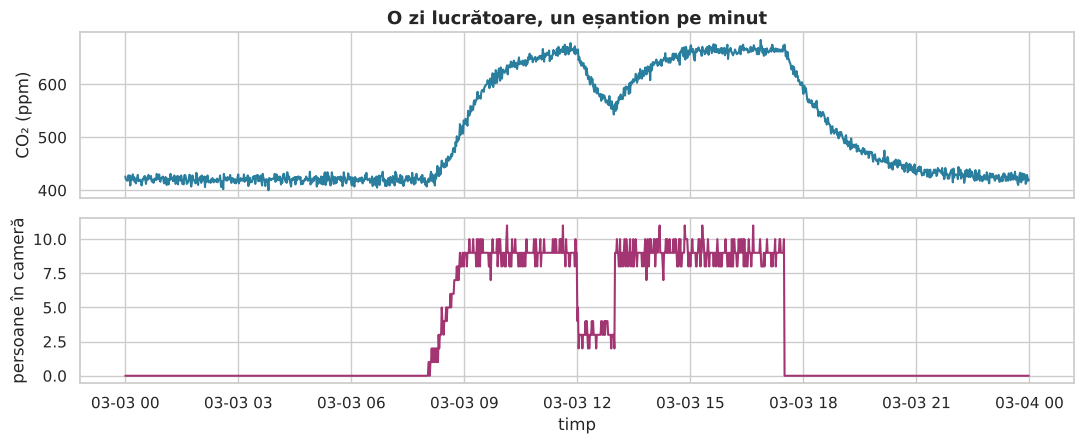

In [2]:
def load_office(path="smart_office_dataset.csv"):
    d = pd.read_csv(path, parse_dates=["timestamp"]).set_index("timestamp")
    d.loc[d.temp_c < 0, "temp_c"] = np.nan                                   # cod de eroare al senzorului
    d.loc[(d.co2_ppm < 300) | (d.co2_ppm > 1500), "co2_ppm"] = np.nan        # citiri false
    cols = ["temp_c", "humidity_pct", "co2_ppm"]
    d[cols] = d[cols].interpolate(limit=60, method="time")                   # doar goluri scurte
    return d

d = load_office()
print(d.shape, "| de la", d.index[0], "până la", d.index[-1])
print(d.head(3))
fig, ax = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True)
day = d.loc["2026-03-03"]
ax[0].plot(day.co2_ppm, color=BLUE); ax[0].set(ylabel="CO₂ (ppm)", title="O zi lucrătoare, un eșantion pe minut")
ax[1].plot(day.occupancy, color=PINK); ax[1].set(ylabel="persoane în cameră", xlabel="timp")
plt.tight_layout(); plt.show()

Semnalul are **1440 de eșantioane pe zi**, iar ținta (persoanele) se schimbă de câteva ori pe zi. Un model nu poate lua 1440 de numere pentru fiecare decizie. Rezumăm tronsoane scurte ale semnalului — *ferestre* — cu câteva numere.

## 1.2 · Ferestre: lungimea, pasul și numărul de ferestre

O fereastră are `L` eșantioane consecutive; următoarea începe după `hop` eșantioane.

* `hop = L` → ferestre **fără suprapunere** (varianta noastră implicită);
* `hop < L` → ferestre **suprapuse** (mai multe rânduri, dar rândurile vecine sunt *aproape același exemplu* — vezi 1.5).

Cu `N` eșantioane, numărul de ferestre complete este

$$n_w = \left\lfloor \frac{N - L}{\text{hop}} \right\rfloor + 1 .$$

In [3]:
N = len(d)
for L, hop in [(15, 15), (15, 5), (60, 60), (60, 15)]:
    nw = (N - L) // hop + 1
    print(f"L = {L:3d} min, hop = {hop:3d} min  ->  {nw:5d} ferestre")

L =  15 min, hop =  15 min  ->    672 ferestre
L =  15 min, hop =   5 min  ->   2014 ferestre
L =  60 min, hop =  60 min  ->    168 ferestre
L =  60 min, hop =  15 min  ->    669 ferestre


## 1.3 · Trăsături, etichetă și grup pentru fiecare fereastră

Pentru fiecare fereastră și fiecare canal de senzor calculăm **trăsături statistice** (media, abaterea standard, minimul, maximul, mediana, RMS, IQR, asimetria, kurtosisul, panta, rata de trecere prin zero, autocorelația de lag 1). Funcția `stat_features(w)` le calculează pentru o fereastră; `window_table` o aplică pe toată înregistrarea și returnează:

* `X` — tabelul de trăsături (un rând pe fereastră);
* `y_people` — numărul mediu de persoane din fereastră;
* `day` — ziua săptămânii, **grupul** nostru.

**Regula de etichetare** este o decizie de proiectare: *o fereastră este „ocupată” dacă numărul mediu de persoane din ea este peste 0,5.* Ferestrele care cuprind o sosire sau o plecare sunt ambigue — numărați-le întotdeauna și raportați-le.

In [4]:
def stat_features(w):
    "trăsăturile statistice ale unei ferestre (vector 1-D)"
    w = np.asarray(w, float); t = np.arange(len(w)); x = w - w.mean(); s = w.std(ddof=1)
    ac1 = np.corrcoef(w[:-1], w[1:])[0, 1] if s > 0 else 0.0
    return dict(mean=w.mean(), std=s, min=w.min(), max=w.max(), median=np.median(w), rms=np.sqrt(np.mean(w ** 2)),
                iqr=np.subtract(*np.percentile(w, [75, 25])), skew=stats.skew(w) if s > 0 else 0.0,
                kurt=stats.kurtosis(w) if s > 0 else 0.0, slope=np.polyfit(t, w, 1)[0],
                zcr=np.mean(np.diff(np.sign(x)) != 0), ac1=ac1 if np.isfinite(ac1) else 0.0)

SHORT = dict(temp_c="tin", humidity_pct="hum", co2_ppm="co2", temp_out_c="tout")
def window_table(d, cols, L=15, hop=15, label="occupancy"):
    rows, ys, days, t0 = [], [], [], []
    A = {c: d[c].values for c in cols}; lab = d[label].values
    for s in range(0, len(d) - L + 1, hop):
        r = {}
        for c in cols:
            for k, v in stat_features(A[c][s:s + L]).items(): r[f"{SHORT[c]}_{k}"] = v
        rows.append(r); ys.append(float(np.mean(lab[s:s + L]))); days.append(d.index[s].dayofweek); t0.append(d.index[s])
    return pd.DataFrame(rows, index=t0).fillna(0.0), np.array(ys), np.array(days)

cols = ["temp_c", "humidity_pct", "co2_ppm"]
X, y_people, day = window_table(d, cols, L=15, hop=15)
y = (y_people > 0.5).astype(int)
print("tabelul X:", X.shape, "(ferestre x trăsături)")
print("ferestre ocupate:", y.sum(), f"({y.mean():.1%})   grupuri (zile):", np.unique(day))
raw = d.occupancy.values[: len(X) * 15].reshape(-1, 15)
straddle = ((raw > 0).any(axis=1) & (raw == 0).any(axis=1)).sum()
print("ferestre care conțin și minute goale, și minute ocupate:", straddle)
X.iloc[:3, :6].round(2)

tabelul X: (672, 36) (ferestre x trăsături)
ferestre ocupate: 206 (30.7%)   grupuri (zile): [0 1 2 3 4 5 6]
ferestre care conțin și minute goale, și minute ocupate: 5


,tin_mean,tin_std,tin_min,tin_max,tin_median,tin_rms
2026-03-02 00:00:00,18.84,0.16,18.60,19.14,18.86,18.84
2026-03-02 00:15:00,18.37,0.12,18.14,18.56,18.37,18.37
2026-03-02 00:30:00,18.06,0.12,17.77,18.21,18.09,18.06


**Cum citim tabelul.** Fiecare rând este o fereastră de 15 minute descrisă prin 36 de numere (3 canale × 12 trăsături). Zilele de weekend nu conțin ferestre ocupate, deci *clasele sunt dezechilibrate (~31 % ocupat)* și acuratețea simplă ar induce în eroare — vom folosi **acuratețea echilibrată**.

## 1.4 · Alegerea lungimii ferestrei

O fereastră scurtă este **reactivă**, dar zgomotoasă și dă multe rânduri; o fereastră lungă este **stabilă**, dar lentă și dă puține rânduri. O lungime bună se alege pe dovezi, nu din obișnuință. Mai jos, o regresie logistică este evaluată cu **lasă-o-zi-afară** pentru patru lungimi de fereastră (rețeta de evaluare este explicată în Partea 4; deocamdată citiți doar rezultatul).

 L (min)  ferestre  acuratețe echilibrată
       5      2016                  0.978
      15       672                  0.985
      30       336                  0.988
      60       168                  1.000


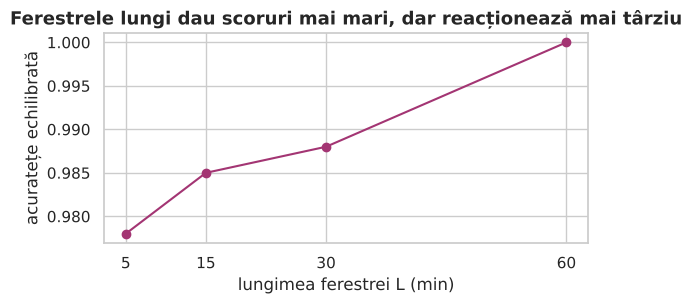

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import balanced_accuracy_score as bacc

lodo = LeaveOneGroupOut(); rows = []
for L in (5, 15, 30, 60):
    Xl, yp, gl = window_table(d, cols, L, L); yl = (yp > 0.5).astype(int)
    pred = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), Xl, yl, cv=lodo, groups=gl)
    rows.append((L, len(Xl), bacc(yl, pred)))
res = pd.DataFrame(rows, columns=["L (min)", "ferestre", "acuratețe echilibrată"]).round(3)
print(res.to_string(index=False))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(res["L (min)"], res["acuratețe echilibrată"], "-o", color=PINK); ax.set(xticks=[5, 15, 30, 60], xlabel="lungimea ferestrei L (min)", ylabel="acuratețe echilibrată", title="Ferestrele lungi dau scoruri mai mari, dar reacționează mai târziu")
plt.tight_layout(); plt.show()

Scorul crește cu `L` — o fereastră mai lungă mediază zgomotul — dar o fereastră de 60 de minute ne poate spune doar că în ultima oră camera *a fost* ocupată și lasă doar 168 de rânduri pentru învățare. **Aplicația decide**: pentru controlul ventilației 15 minute este un compromis rezonabil; păstrăm `L = 15`.

> **Regulă practică.** Alegeți `L` din *scara de timp a fenomenului* (aici: sosiri și plecări, de la minute la ore) și din *întârzierea pe care aplicația o tolerează*, apoi verificați că aveți încă suficiente ferestre (≥ 10 pe trăsătură este un minim bun).

## 1.5 · Ferestre suprapuse și scurgere de informație

Cu `hop < L`, ferestrele vecine împart cea mai mare parte din eșantioane. Dacă o împărțire aleatorie pune o fereastră în antrenare și vecina ei în test, modelul este testat pe ceva ce practic a văzut deja. Aceasta este **scurgerea de informație** (*leakage*), iar ea face ca scorul să arate excelent chiar și atunci când nu e nimic de învățat.

O demonstrăm pe date **fără niciun semnal**: 24 de blocuri de zgomot autocorelat, fiecare cu o etichetă *aleatoare*. Orice scor onest trebuie să fie 0,5.

In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import KFold

rng = np.random.default_rng(0); n_blocks, B, Lw, hop = 24, 600, 60, 6
lab = rng.integers(0, 2, n_blocks); series = []
for b in range(n_blocks):
    e = rng.normal(size=B); ar = np.zeros(B)
    for i in range(1, B): ar[i] = 0.9 * ar[i - 1] + e[i]                  # zgomot autocorelat
    series.append(ar + rng.normal())                                       # + un nivel specific blocului
feats, ys, grp = [], [], []
for b, s in enumerate(series):
    for st in range(0, B - Lw + 1, hop):                                   # ferestre puternic suprapuse
        feats.append(stat_features(s[st:st + Lw])); ys.append(lab[b]); grp.append(b)
Xn, yn, gn = pd.DataFrame(feats), np.array(ys), np.array(grp)
print("ferestre:", len(Xn), "| etichetele sunt aleatoare: nu se poate învăța nimic")
for name, cv, kw in [("5 fold-uri aleatorii", KFold(5, shuffle=True, random_state=0), {}), ("pe grupuri (un bloc lăsat afară)", LeaveOneGroupOut(), dict(groups=gn))]:
    pred = cross_val_predict(DecisionTreeClassifier(random_state=0), Xn, yn, cv=cv, **kw)
    print(f"{name:34s} acuratețe echilibrată = {bacc(yn, pred):.3f}")

ferestre: 2184 | etichetele sunt aleatoare: nu se poate învăța nimic
5 fold-uri aleatorii               acuratețe echilibrată = 0.782


pe grupuri (un bloc lăsat afară)   acuratețe echilibrată = 0.446


Împărțirea aleatorie raportează ≈ 0,78 pe zgomot pur; împărțirea pe grupuri raportează ≈ 0,45, adevărul. **Ori de câte ori ferestrele se suprapun, sau mai multe ferestre provin din aceeași zi / mașină / pacient, împărțiți pe grupuri.** Tabelul nostru smart office folosește ferestre fără suprapunere și grupează pe zile — de aceea putem avea mai multă încredere în scorurile lui.

> **Ce am învățat în Partea 1.** Un tabel se construiește din ferestre; `L` și `hop` sunt alegeri de proiectare justificate de aplicație; regula de etichetare trebuie scrisă; **grupul** însoțește tabelul și decide cum împărțim datele.

# Partea 2 — Trei familii de trăsături

Statisticile descriu **amplitudinea** unei ferestre; spectrul descrie **ce frecvențe** conține; wavelet-urile descriu **ce frecvențe și când**. Probleme diferite își ascund informația în familii diferite, iar singura cale de a ști care este cea potrivită este să le **testăm**.

Folosim **simulatorul pentru functionarea unui rulment**: o fereastră de 1 s eșantionată la *fs* = 2000 Hz (2000 de eșantioane). Un rulment sănătos vibrează la frecvența arborelui (≈ 30 Hz) plus zgomot. Unul defect adaugă un tren de impacturi scurte (≈ 87 pe secundă) care excită o rezonanță în jur de 600 Hz, iar semnalul defect este făcut puțin mai slab astfel încât **RMS-ul lui se suprapune** cu cel sănătos, ca în datele reale.

## 2.1 · Semnalele simulate

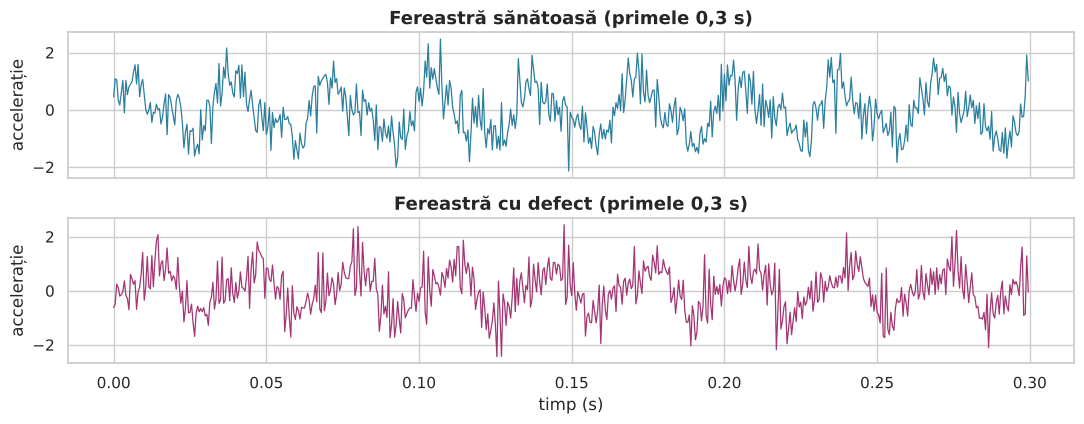

ferestre: (300, 2000) | defecte: 150
RMS sănătos  min/max: 0.72 1.06
RMS defect   min/max: 0.68 1.05


In [7]:
FS = 2000
def make_bearing(n_per=150, seed=0):
    "label 0 = sănătos, 1 = defect. X: (2 * n_per) x 2000 eșantioane"
    r = np.random.default_rng(seed); t = np.arange(2000) / FS; X, y = [], []
    for lab in (0, 1):
        for _ in range(n_per):
            f0 = r.uniform(29, 31); a = r.uniform(0.8, 1.2)
            x = a * np.sin(2 * np.pi * f0 * t + r.uniform(0, 6.28)) + 0.4 * a * np.sin(2 * np.pi * 2 * f0 * t + r.uniform(0, 6.28))
            x += r.normal(0, r.uniform(0.35, 0.55), 2000)
            if lab == 1:
                bp = r.uniform(84, 90); amp = r.uniform(0.9, 1.8); fr = r.uniform(560, 640)    # rata impacturilor, mărimea, rezonanța
                k = np.arange(0, 0.012, 1 / FS); imp = np.exp(-k / 0.004) * np.sin(2 * np.pi * fr * k)
                imps = np.zeros(2000)
                for e in np.arange(r.uniform(0, 1 / bp), 1, 1 / bp):
                    i = int(e * FS); m = min(len(imp), 2000 - i)
                    if m > 0: imps[i:i + m] += imp[:m] * amp * r.uniform(0.7, 1.3)
                x = x + imps; x *= r.uniform(0.80, 0.92)
            X.append(x); y.append(lab)
    return np.array(X), np.array(y)

Xb, yb = make_bearing(150, 0)
t = np.arange(2000) / FS
fig, ax = plt.subplots(2, 1, figsize=(11, 4.4), sharex=True)
ax[0].plot(t[:600], Xb[0, :600], color=BLUE, lw=0.9); ax[0].set(title="Fereastră sănătoasă (primele 0,3 s)", ylabel="accelerație")
ax[1].plot(t[:600], Xb[-1, :600], color=PINK, lw=0.9); ax[1].set(title="Fereastră cu defect (primele 0,3 s)", ylabel="accelerație", xlabel="timp (s)")
plt.tight_layout(); plt.show()
print("ferestre:", Xb.shape, "| defecte:", yb.sum())
print("RMS sănătos  min/max:", np.sqrt((Xb[yb == 0] ** 2).mean(1)).min().round(2), np.sqrt((Xb[yb == 0] ** 2).mean(1)).max().round(2))
print("RMS defect   min/max:", np.sqrt((Xb[yb == 1] ** 2).mean(1)).min().round(2), np.sqrt((Xb[yb == 1] ** 2).mean(1)).max().round(2))

Cu ochiul liber, fereastra defectă are vârfuri ascuțite, dar **domeniile RMS se suprapun**: un prag pe RMS nu poate separa clasele. Avem nevoie de trăsături mai bune.

## 2.2 · Trăsături în domeniul timp (statistice)

Șase trăsături clasice ale unei ferestre `x` cu *N* eșantioane:

| Trăsătura | Formula | Ce detectează |
|---|---|---|
| RMS | $\sqrt{\tfrac1N\sum x_i^2}$ | energia totală |
| std | împrăștierea în jurul mediei | energia fără nivelul constant |
| kurtosis | $\tfrac{\frac1N\sum (x_i-\bar x)^4}{\sigma^4}-3$ | *ascuțimea*: impulsurile o fac să crească |
| factor de vârf (crest) | $\max|x| / \text{RMS}$ | înălțimea celui mai înalt vârf |
| vârf-la-vârf | $\max x-\min x$ | intervalul total |
| rata de trecere prin zero | ponderea schimbărilor de semn | frecvența dominantă, aproximativ |

Două verificări pe semnale cunoscute ne spun la ce să ne așteptăm: o sinusoidă de amplitudine *A* are RMS = *A*/√2 ≈ 0,707 *A* și kurtosis = −1,5; zgomotul gaussian are kurtosis 0.

In [8]:
def time_features(x):
    x = np.asarray(x, float); rms = np.sqrt(np.mean(x ** 2))
    return dict(rms=rms, std=x.std(), kurt=stats.kurtosis(x), crest=np.max(np.abs(x)) / rms, pp=np.ptp(x),
                zcr=np.mean(np.diff(np.sign(x - x.mean())) != 0))

sine = 2 * np.sin(2 * np.pi * 50 * t); noise = np.random.default_rng(1).normal(size=2000)
print("sinusoidă, A = 2 :", {k: round(float(v), 3) for k, v in time_features(sine).items() if k in ("rms", "kurt", "crest")})
print("zgomot gaussian  :", {k: round(float(v), 3) for k, v in time_features(noise).items() if k in ("rms", "kurt", "crest")})
TF = pd.DataFrame([time_features(x) for x in Xb])
print(TF.groupby(yb).mean().round(3).rename(index={0: "sănătos", 1: "defect"}))

sinusoidă, A = 2 : {'rms': 1.414, 'kurt': -1.5, 'crest': 1.414}
zgomot gaussian  : {'rms': 1.007, 'kurt': 0.038, 'crest': 3.727}
           rms    std   kurt  crest     pp    zcr
sănătos  0.888  0.888 -0.618  2.917  4.837  0.196
defect   0.841  0.841 -0.377  3.235  5.058  0.265


**Kurtosisul** ferestrelor defecte este mai mare în medie (−0,38 față de −0,62; impacturile fac distribuția ascuțită), factorul de vârf crește, iar RMS-ul chiar scade puțin. Totuși, ferestrele individuale se suprapun — de aceea vom cuantifica totul în 2.5.

## 2.3 · Trăsături de frecvență: spectrul

Transformata Fourier exprimă o fereastră ca o sumă de sinusoide. Patru puncte de reținut:

* **Limita Nyquist:** cu frecvența de eșantionare *fs* vedem doar frecvențe până la *fs*/2 (aici 1000 Hz). Frecvențele mai mari se *aliază* peste cele mai mici.
* **Rezoluția în frecvență:** o fereastră de *N* eșantioane dă canale distanțate cu *Δf* = *fs*/*N* (aici 1 Hz pentru fereastra întreagă; 3,9 Hz pentru segmentele de 512 eșantioane din Welch).
* **Fereastra de ponderare:** o tăiere abruptă a semnalului creează artefacte („scurgere spectrală”); înmulțim segmentul cu o fereastră netezită (Hann).
* **Metoda Welch:** mediază spectrele unor segmente suprapuse → o estimare netedă, cu varianță mică, a **densității spectrale de putere**.

Din spectru luăm **puterile pe benzi** (puterea în anumite benzi de frecvență — benzile sunt o *alegere de proiectare* ghidată de fizică), **centroidul spectral** („centrul de masă” al spectrului), **frecvența dominantă** și **planeitatea spectrală** (1 = zgomot alb, aproape de 0 = câteva vârfuri puternice).

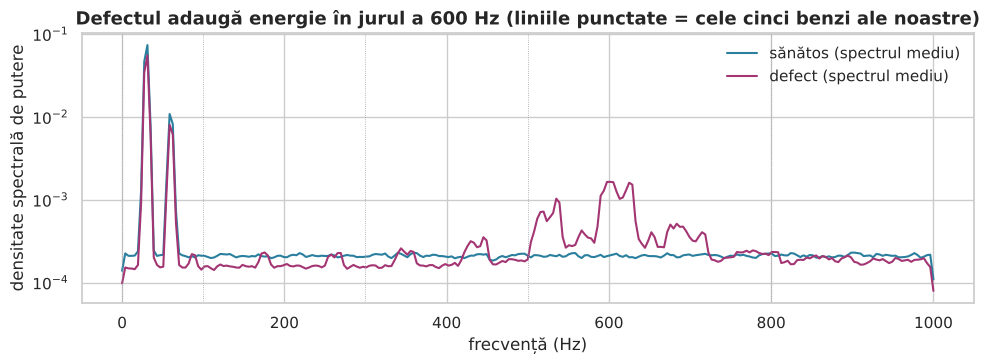

rezoluția în frecvență (Welch, 512 eșantioane): 3.91 Hz | Nyquist: 1000.0 Hz
             sănătos   defect
bp_0_100       0.605    0.451
bp_100_300     0.042    0.033
bp_300_500     0.042    0.039
bp_500_800     0.064    0.152
bp_800_1000    0.042    0.038
centroid     159.982  235.763
domf          30.573   30.703
flat           0.273    0.288


In [9]:
f, Ph = signal.welch(Xb[yb == 0], FS, nperseg=512, window="hann"); _, Pf = signal.welch(Xb[yb == 1], FS, nperseg=512, window="hann")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.semilogy(f, Ph.mean(0), color=BLUE, label="sănătos (spectrul mediu)"); ax.semilogy(f, Pf.mean(0), color=PINK, label="defect (spectrul mediu)")
for lo, hi in [(0, 100), (100, 300), (300, 500), (500, 800), (800, 1000)]: ax.axvline(lo, color=GREY, lw=0.6, ls=":")
ax.set(xlabel="frecvență (Hz)", ylabel="densitate spectrală de putere", title="Defectul adaugă energie în jurul a 600 Hz (liniile punctate = cele cinci benzi ale noastre)"); ax.legend()
plt.tight_layout(); plt.show()
print("rezoluția în frecvență (Welch, 512 eșantioane):", round(f[1] - f[0], 2), "Hz | Nyquist:", FS / 2, "Hz")

def spec_features(x, bands=((0, 100), (100, 300), (300, 500), (500, 800), (800, 1000))):
    f, P = signal.welch(x, FS, nperseg=512, window="hann"); df = f[1] - f[0]; d = {}
    for lo, hi in bands: d[f"bp_{lo}_{hi}"] = P[(f >= lo) & (f < hi)].sum() * df
    pn = P / P.sum(); d["centroid"] = (f * pn).sum(); d["domf"] = f[np.argmax(P)]
    d["flat"] = np.exp(np.mean(np.log(P + 1e-12))) / np.mean(P)
    return d
SF = pd.DataFrame([spec_features(x) for x in Xb])
print(SF.groupby(yb).mean().round(3).rename(index={0: "sănătos", 1: "defect"}).T)

Ambele clase au aceeași frecvență dominantă (≈ 30 Hz, arborele) — inutilă pentru diagnostic. Trăsătura informativă este **puterea în banda 500–800 Hz**, care mai mult decât se dublează din cauza defectului.

## 2.4 · Trăsături timp–frecvență: wavelet-uri

Un spectru spune *ce* frecvențe sunt prezente, nu *când*. O descompunere wavelet împarte semnalul în **niveluri**, fiecare acoperind o bandă care se înjumătățește la fiecare nivel și păstrându-și rezoluția în timp. Un rezumat practic este **energia pe nivel**, relativă la total. Pentru *fs* = 2000 Hz și 5 niveluri, benzile sunt:

| Coeficienți | Banda (Hz) | Rol |
|---|---|---|
| `cA5` (aproximare) | 0–31 | frecvența arborelui și tendințe lente |
| `cD5` | 31–62 | armonica a 2-a a arborelui |
| `cD4` | 62–125 | rata impacturilor (≈ 87 Hz) |
| `cD3` | 125–250 | — |
| `cD2` | 250–500 | — |
| `cD1` | 500–1000 | **rezonanța rulmentului (≈ 600 Hz)** |

Regula este: *nivelul de detaliu j acoperă fs/2^(j+1) … fs/2^j.* Alegeți wavelet-ul (`db4`) și adâncimea astfel încât banda de interes să cadă într-**un singur** nivel.

                sănătos  defect
cA5 (0-31)        0.414   0.337
cD5 (31-62)       0.309   0.267
cD4 (62-125)      0.060   0.053
cD3 (125-250)     0.032   0.029
cD2 (250-500)     0.062   0.088
cD1 (500-1000)    0.123   0.226


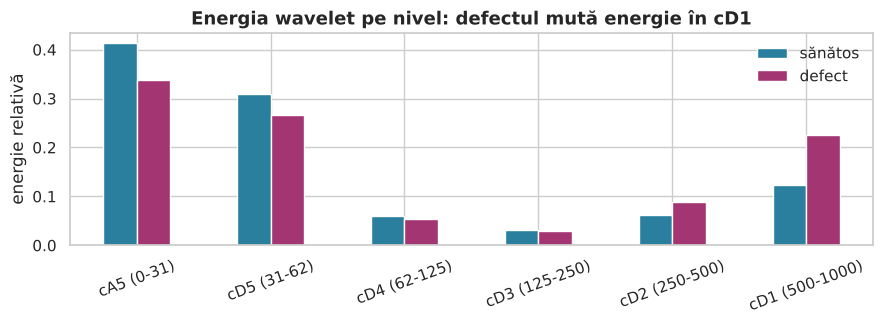

In [10]:
import pywt
def wavelet_energy(x, wavelet="db4", level=5):
    c = pywt.wavedec(x, wavelet, level=level); E = np.array([np.sum(ci ** 2) for ci in c]); E = E / E.sum()
    return {f"wE_{i}": E[i] for i in range(len(E))}
names = ["cA5 (0-31)", "cD5 (31-62)", "cD4 (62-125)", "cD3 (125-250)", "cD2 (250-500)", "cD1 (500-1000)"]
WF = pd.DataFrame([wavelet_energy(x) for x in Xb]); WF.columns = names
M = WF.groupby(yb).mean().rename(index={0: "sănătos", 1: "defect"})
print(M.round(3).T)
fig, ax = plt.subplots(figsize=(9, 3.4)); M.T.plot.bar(ax=ax, color=[BLUE, PINK]); ax.set(ylabel="energie relativă", title="Energia wavelet pe nivel: defectul mută energie în cD1"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## 2.5 · Care familie este cea mai bună? Testați-le

Construim toate cele trei familii pentru cele 300 de ferestre și dăm fiecărei familii *același* model (regresia logistică, explicată în Partea 4) cu aceeași evaluare pe 5 fold-uri. Aici o împărțire aleatorie este acceptabilă pentru că **fiecare fereastră este o înregistrare independentă** (fără suprapunere, fără grup comun).

doar RMS                0.600
doar kurtosis           0.773
domeniul timp (6)       0.780
forma spectrului (3)    0.980
puteri pe benzi (5)     1.000
energii wavelet (6)     0.987
toate 20                1.000


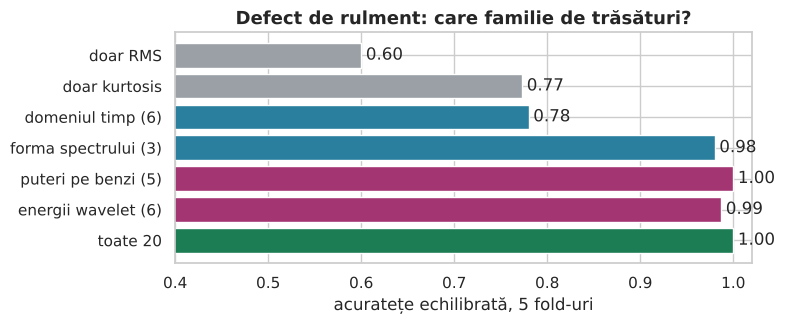

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score as bacc
from sklearn.model_selection import StratifiedKFold, cross_val_predict
F = pd.concat([TF, SF, pd.DataFrame([wavelet_energy(x) for x in Xb])], axis=1)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
def score(cols):
    p = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), F[cols], yb, cv=cv); return bacc(yb, p)
families = {"doar RMS": ["rms"], "doar kurtosis": ["kurt"], "domeniul timp (6)": list(TF.columns), "forma spectrului (3)": ["centroid", "domf", "flat"],
            "puteri pe benzi (5)": [c for c in F if c.startswith("bp_")], "energii wavelet (6)": [c for c in F if c.startswith("wE_")], "toate 20": list(F.columns)}
R = pd.Series({k: score(v) for k, v in families.items()}).round(3)
print(R.to_string())
fig, ax = plt.subplots(figsize=(8, 3.4)); ax.barh(R.index[::-1], R.values[::-1], color=[GREY, GREY, BLUE, BLUE, PINK, PINK, GREEN][::-1]); ax.set(xlim=(0.4, 1.02), xlabel="acuratețe echilibrată, 5 fold-uri", title="Defect de rulment: care familie de trăsături?")
for i, v in enumerate(R.values[::-1]): ax.text(v + 0.005, i, f"{v:.2f}", va="center")
plt.tight_layout(); plt.show()

**Citirea rezultatului.**

* RMS singur (0,60) este abia mai bun decât aruncarea cu banul: amplitudinea ascunde defectul.
* Kurtosisul (0,77) prinde caracterul impulsiv, dar un singur număr este zgomotos.
* Cele cinci **puteri pe benzi** (1,00) și cele șase **energii wavelet** (0,99) câștigă pentru că privesc *domeniul potrivit de frecvență*.
* Folosirea tuturor celor 20 de trăsături nu bate cea mai bună familie — **mai multe trăsături nu înseamnă mai bine**, ceea ce ne duce direct la Partea 3.

> **Ce am învățat în Partea 2.** Statistici = amplitudine; spectru = frecvențe (atenție la limita Nyquist, la rezoluția fs/N și la fereastra de ponderare); wavelet-uri = frecvențe și timp. Alegeți familia din **fizica fenomenului** și confirmați cu un test corect.

# Partea 3 — Selecția trăsăturilor

După Partea 1–2 putem avea zeci sau sute de coloane. Păstrarea tuturor are un cost: modelele **supraantrenează** (mai multe coloane decât pot susține datele), rezultatele devin **greu de explicat**, iar fiecare trăsătură trebuie măsurată și calculată în producție. **Selecția trăsăturilor** păstrează un subset mic care poartă informația.

Trei familii, ordonate de la ieftin la scump:

| Familia | Cum decide | Cost | Slăbiciune |
|---|---|---|---|
| **Filtru** | evaluează fiecare trăsătură *separat* (varianță, corelație cu ținta, informație mutuală) | foarte mic | ignoră redundanța: alege cinci copii ale aceleiași informații |
| **Wrapper** | antrenează un model pe subseturi candidate (RFE, selecție înainte) | mare | supraantrenează selecția dacă nu este validată |
| **Încorporată** | selecția are loc *în timpul* antrenării (penalizare L1, importanțe din arbori) | mic | depinde de model; instabilă pentru trăsături corelate |

Lucrăm pe tabelul biroului inteligent din Partea 1 (672 de ferestre × 36 de trăsături). Fixăm mai întâi `X`, `y`, `day`.

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.metrics import balanced_accuracy_score as bacc
from functools import partial
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif, RFE, SequentialFeatureSelector

d = load_office(); cols = ["temp_c", "humidity_pct", "co2_ppm"]
X, y_people, day = window_table(d, cols, 15, 15); y = (y_people > 0.5).astype(int)
lodo = LeaveOneGroupOut()
def lodo_score(model, X=X):
    "acuratețea echilibrată a lui `model` cu lasă-o-zi-afară"
    return bacc(y, cross_val_predict(model, X, y, cv=lodo, groups=day))
print(X.shape, "| ocupat:", y.mean().round(3))

(672, 36) | ocupat: 0.307


## 3.1 · Metode de tip filtru

**Pasul 1 – eliminăm ce este inutil.** O coloană cu varianță (aproape) zero nu poartă nimic. **Pasul 2 – evaluăm restul.** Scorurile univariate clasice sunt **corelația Pearson** absolută cu ținta și **informația mutuală** (care prinde și dependențele neliniare).

In [13]:
print("coloane cu varianță zero:", int((X.std() < 1e-9).sum()))
corr_y = X.apply(lambda c: abs(np.corrcoef(c, y)[0, 1])).sort_values(ascending=False)
mi = pd.Series(mutual_info_classif(X, y, random_state=0), index=X.columns).sort_values(ascending=False)
print(pd.DataFrame({"|corelație cu y|": corr_y.head(8).round(3), "trăsătura (MI)": mi.head(8).index, "informație mutuală": mi.head(8).round(3).values}).to_string())

coloane cu varianță zero: 0
            |corelație cu y| trăsătura (MI)  informație mutuală
tin_min                0.869        tin_min               0.450
tin_mean               0.867        tin_rms               0.448
tin_rms                0.867       tin_mean               0.448
tin_median             0.866     tin_median               0.447
tin_max                0.863        tin_max               0.445
co2_max                0.863        co2_rms               0.425
co2_rms                0.862       co2_mean               0.422
co2_mean               0.862        co2_max               0.421


Trăsăturile din frunte sunt toate de tip **nivel al temperaturii** (`tin_min`, `tin_mean`, `tin_rms`, `tin_median`, `tin_max`) și de nivel al CO₂. Sunt aproape **aceeași coloană**: într-o fereastră de 15 minute media, mediana, minimul și maximul unui semnal care variază lent sunt aproape egale. Aceasta este **problema redundanței** la filtre, pe care o putem măsura:

perechi de trăsături: 630 | perechi cu |r| > 0,95: 69 | > 0,90: 80


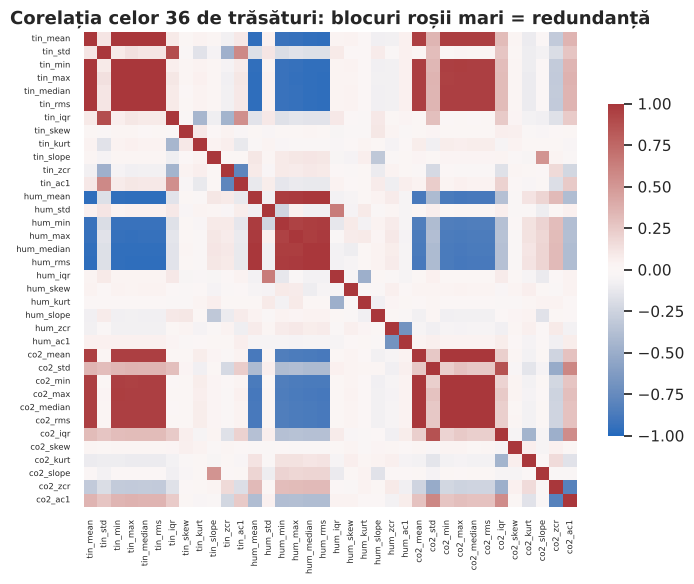

In [14]:
C = X.corr().abs(); upper = C.values[np.triu_indices(len(C), 1)]
print("perechi de trăsături:", len(upper), "| perechi cu |r| > 0,95:", int((upper > 0.95).sum()), "| > 0,90:", int((upper > 0.90).sum()))
fig, ax = plt.subplots(figsize=(7.2, 6))
sns.heatmap(X.corr(), cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.7})
ax.tick_params(labelsize=6); ax.set_title("Corelația celor 36 de trăsături: blocuri roșii mari = redundanță")
plt.tight_layout(); plt.show()

**Concluzii.** Aproximativ 70 din cele 630 de perechi au corelație peste 0,95. Un filtru care păstrează „cele mai bune 5” păstrează cinci copii ale unei singure idei. Putem testa pagubele: alegem top-5 trăsături **în interiorul** unui pipeline (astfel încât selecția să vadă doar zilele de antrenare, vezi 3.4) și comparăm cu toate cele 36 de trăsături.

In [15]:
LR = lambda: LogisticRegression(max_iter=3000)
print("toate cele 36 de trăsături        :", round(lodo_score(make_pipeline(StandardScaler(), LR())), 3))
print("filtru: top 5 după testul F       :", round(lodo_score(make_pipeline(StandardScaler(), SelectKBest(f_classif, k=5), LR())), 3))
print("filtru: top 10 după testul F      :", round(lodo_score(make_pipeline(StandardScaler(), SelectKBest(f_classif, k=10), LR())), 3))
print("filtru: top 5 după informația mut.:", round(lodo_score(make_pipeline(StandardScaler(), SelectKBest(partial(mutual_info_classif, random_state=0), k=5), LR())), 3))

toate cele 36 de trăsături        : 0.985
filtru: top 5 după testul F       : 0.917
filtru: top 10 după testul F      : 0.922


filtru: top 5 după informația mut.: 0.93


Filtrele univariate pierd ≈ 6 puncte (0,92–0,93 față de 0,985): au ales trăsături redundante și au ratat trăsăturile de *pantă* care ne spun că încăperea **se umple** (CO₂ crește, temperatura se schimbă). O soluție bună este să **eliminăm întâi redundanța** (de exemplu păstrăm o trăsătură din fiecare grup cu |r| > 0,95) sau să folosim o metodă care privește trăsăturile **împreună**.

## 3.2 · Metode wrapper: RFE și selecția înainte

* **RFE** (eliminare recursivă a trăsăturilor) antrenează un model pe toate trăsăturile, elimină trăsătura cu cea mai mică pondere, reantrenează și repetă până rămân *k*.
* **Selecția înainte** pornește de la nimic și adaugă, la fiecare pas, trăsătura care îmbunătățește cel mai mult scorul validat încrucișat.

Amândouă judecă trăsăturile **în prezența celorlalte**, deci copiile redundante sunt eliminate. Sunt mai costisitoare (multe antrenări de model).

In [16]:
Zs = StandardScaler().fit_transform(X)
rfe = RFE(LR(), n_features_to_select=5).fit(Zs, y)
print("RFE păstrează:", list(X.columns[rfe.support_]))
print("RFE, 5 trăsături (în interiorul LODO):", round(lodo_score(make_pipeline(StandardScaler(), RFE(LR(), n_features_to_select=5), LR())), 3))
print("selecție înainte, 5 trăsături (în interiorul LODO):", round(lodo_score(make_pipeline(StandardScaler(), SequentialFeatureSelector(LR(), n_features_to_select=5, cv=3), LR())), 3))

RFE păstrează: ['tin_mean', 'tin_min', 'tin_rms', 'co2_max', 'co2_slope']


RFE, 5 trăsături (în interiorul LODO): 0.972


selecție înainte, 5 trăsături (în interiorul LODO): 0.968


Cu doar **5 trăsături**, RFE și selecția înainte ajung la 0,97 — aproape de toate cele 36 (0,985) — iar setul ales combină *nivelul* (`tin_mean`, `co2_max`) cu *dinamica* (`co2_slope`).

## 3.3 · Metode încorporate: L1 și arbori

O regresie logistică cu **penalizare L1** adaugă o presiune $\sum |w_j|$, controlată de `C`, asupra ponderilor și împinge multe ponderi exact la **zero** — selecția are loc în timpul antrenării. Cu cât `C` este mai mic, cu atât mai puține trăsături supraviețuiesc. Un arbore de decizie raportează **importanțe**: cât a redus fiecare trăsătură impuritatea în diviziuni.

L1 (C = 0,1) păstrează 5 din 36 de trăsături: ['tin_min', 'tin_slope', 'co2_mean', 'co2_min', 'co2_slope']
L1 în interiorul LODO: 0.981
tin_mean     0.744
tin_slope    0.140
co2_slope    0.094
hum_max      0.014
tin_iqr      0.008


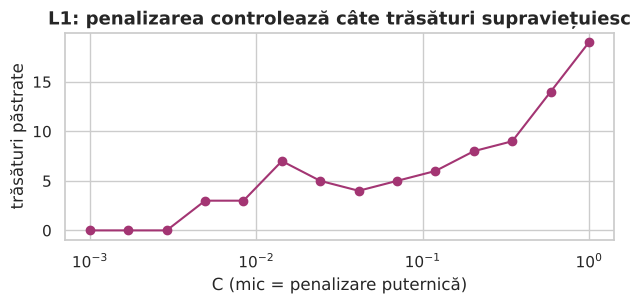

In [17]:
l1 = LogisticRegression(penalty="l1", solver="liblinear", C=0.1, random_state=0).fit(Zs, y)
print("L1 (C = 0,1) păstrează", int((l1.coef_ != 0).sum()), "din 36 de trăsături:", list(X.columns[(l1.coef_ != 0)[0]]))
print("L1 în interiorul LODO:", round(lodo_score(make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=0.1, random_state=0))), 3))
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(max_depth=4, random_state=0).fit(X, y)
print(pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False).head(5).round(3).to_string())

Cs = np.logspace(-3, 0, 14); nz = [(LogisticRegression(penalty="l1", solver="liblinear", C=c, random_state=0).fit(Zs, y).coef_ != 0).sum() for c in Cs]
fig, ax = plt.subplots(figsize=(6.4, 3.2)); ax.semilogx(Cs, nz, "-o", color=PINK); ax.set(xlabel="C (mic = penalizare puternică)", ylabel="trăsături păstrate", title="L1: penalizarea controlează câte trăsături supraviețuiesc")
plt.tight_layout(); plt.show()

L1 păstrează **5** trăsături, din nou un amestec de nivel și dinamică (de exemplu `tin_min`, `co2_min`, `tin_slope`, `co2_slope`), cu scorul 0,98. Arborele pune 74 % din importanță pe `tin_mean`: îi trebuie doar o trăsătură de nivel plus două pante.

## 3.4 · Cea mai importantă regulă: selectați **în interiorul** validării încrucișate

Selecția folosește etichetele, deci face parte din model. Dacă alegeți trăsăturile pe *toate* datele și *apoi* validați încrucișat, zilele de test au influențat deja alegerea — scorul este **părtinitor optimist**, uneori dramatic. Dovada: 100 de exemple, 500 de trăsături, **etichete aleatorii** (acuratețea cinstită = 0,5).

In [18]:
rng = np.random.default_rng(0); Xn = rng.normal(size=(100, 500)); yn = rng.integers(0, 2, 100)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
Xs = SelectKBest(f_classif, k=10).fit_transform(Xn, yn)                                 # GREȘIT: selecția vede toate etichetele
wrong = cross_val_score(LR(), Xs, yn, cv=cv, scoring="balanced_accuracy").mean()
right = cross_val_score(make_pipeline(SelectKBest(f_classif, k=10), LR()), Xn, yn, cv=cv, scoring="balanced_accuracy").mean()
print(f"selecție în afara CV (greșit)     : {wrong:.3f}")
print(f"selecție în interiorul pipeline-ului: {right:.3f}   <- adevărul: nu există nimic de învățat")

selecție în afara CV (greșit)     : 0.731
selecție în interiorul pipeline-ului: 0.482   <- adevărul: nu există nimic de învățat


Rețeta „greșită” raportează ≈ 0,73 pe zgomot. Pipeline-ul reantrenează selectorul **doar pe fold-urile de antrenare** și returnează ≈ 0,48. Aceasta este regula scurgerii de informație din Cursul 6, acum în cod: *tot ce învață din date — scalerul, selectorul, modelul, căutarea hiperparametrilor — intră în pipeline.*

## 3.5 · Este selecția stabilă?

Dacă setul selectat se schimbă complet de la un set de antrenare la altul, nu ar trebui să-l interpretăm. Repetăm selecția L1 în fiecare dintre cele 7 seturi de antrenare lasă-o-zi-afară și numărăm de câte ori supraviețuiește fiecare trăsătură.

tin_min       7
co2_slope     7
co2_min       7
tin_slope     7
co2_mean      4
co2_max       3
tin_mean      0
tin_std       0
tin_max       0
tin_median    0


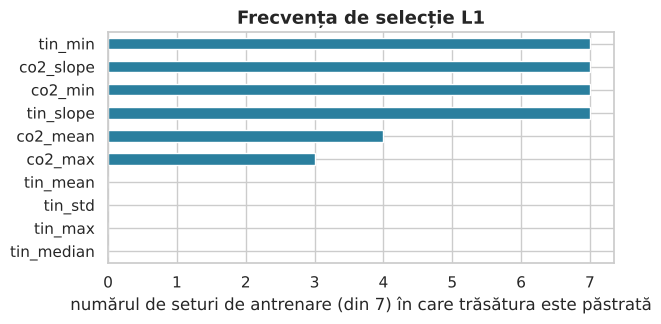

In [19]:
count = pd.Series(0, index=X.columns)
for tr_i, te_i in lodo.split(X, y, day):
    sc_ = StandardScaler().fit(X.iloc[tr_i]); m = LogisticRegression(penalty="l1", solver="liblinear", C=0.1, random_state=0).fit(sc_.transform(X.iloc[tr_i]), y[tr_i])
    count += (m.coef_[0] != 0)
st = count.sort_values(ascending=False).head(10)
print(st.to_string())
fig, ax = plt.subplots(figsize=(6.4, 3.4)); st[::-1].plot.barh(ax=ax, color=BLUE); ax.set(xlabel="numărul de seturi de antrenare (din 7) în care trăsătura este păstrată", title="Frecvența de selecție L1")
plt.tight_layout(); plt.show()

Patru trăsături (`tin_min`, `tin_slope`, `co2_min`, `co2_slope`) sunt păstrate în **toate cele 7** fold-uri: stabile și demne de interpretat. Trăsăturile de *nivel* `co2_max`, `co2_mean`, `co2_rms` apar și dispar — sunt copii interschimbabile una pentru alta, deci L1 alege una dintre ele arbitrar. **Nu interpretați niciodată ponderea unei singure trăsături dintr-un grup de trăsături corelate.**

> **Ce am învățat în Partea 3.** Filtrele sunt rapide, dar oarbe la redundanță; wrapper-ele și L1 privesc trăsăturile împreună; selecția face parte din model și trăiește **în interiorul** pipeline-ului; verificați că setul ales este **stabil**. Un subset mic și stabil este mai util decât unul mare: costă mai puțin, se explică mai ușor și este aproape la fel de precis.

# Partea 4 — Primul vostru model

Avem acum un tabel (`X`, `y`, `day`). Un **model** este o funcție $\hat y = f(x;\theta)$ cu *parametri* θ învățați din date prin minimizarea unei **funcții de pierdere** pe exemplele de antrenare. Această parte arată rutina completă pe tabelul biroului inteligent — ordinea pașilor contează mai mult decât modelul:

1. o **linie de bază** (ce scor are un predictor trivial);
2. un **model simplu** cu o evaluare corectă;
3. un **diagnostic** (subantrenare sau supraantrenare?) și un remediu;
4. un **tabel de rezultate** care pune totul alături.

Pregătire: același tabel ca în Partea 3 și o funcție de evaluare care returnează acuratețea echilibrată **pe date nevăzute** cu *lasă-o-zi-afară* (fiecare zi este o dată setul de test, modelul se antrenează pe celelalte șase).

In [20]:
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.model_selection import LeaveOneGroupOut, KFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score as bacc, accuracy_score, confusion_matrix, mean_absolute_error as mae

d = load_office(); cols = ["temp_c", "humidity_pct", "co2_ppm"]
X, y_people, day = window_table(d, cols, 15, 15); y = (y_people > 0.5).astype(int)
lodo = LeaveOneGroupOut()

def heldout(model, X=X, y=y):
    "predicții pe date nevăzute cu lasă-o-zi-afară"
    return cross_val_predict(model, X, y, cv=lodo, groups=day)
def train_score(model, X=X, y=y):
    "acuratețea echilibrată medie pe setul de antrenare, pe cele 7 fold-uri"
    return float(np.mean([bacc(y[a], model.fit(X.iloc[a], y[a]).predict(X.iloc[a])) for a, b in lodo.split(X, y, day)]))
print(X.shape, "| ponderea ocupat:", round(y.mean(), 3))

(672, 36) | ponderea ocupat: 0.307


## 4.1 · Mai întâi liniile de bază

Un scor nu înseamnă nimic singur. O **acuratețe de 0,93** este excelentă când linia de bază este 0,50 și slabă când este 0,92. Două linii de bază pe care ar trebui să le aibă orice problemă de clasificare:

* **clasa majoritară** — răspunde mereu cu cea mai frecventă clasă;
* **o regulă cu o trăsătură** — un singur prag pe cea mai informativă trăsătură (un arbore de adâncime 1 este exact asta).

In [21]:
pred = heldout(DummyClassifier(strategy="most_frequent"))
acc, ba = accuracy_score(y, pred), bacc(y, pred)
print(f"mereu 'gol'      : acuratețe = {acc:.3f}   acuratețe echilibrată = {ba:.3f}")
for f in ["co2_mean", "tin_mean"]:
    ba = bacc(y, heldout(DecisionTreeClassifier(max_depth=1), X[[f]]))
    print(f"prag pe {f:9s}: acuratețe echilibrată = {ba:.3f}")

mereu 'gol'      : acuratețe = 0.693   acuratețe echilibrată = 0.500
prag pe co2_mean : acuratețe echilibrată = 0.917
prag pe tin_mean : acuratețe echilibrată = 0.931


Răspunsul constant „gol” obține **69 % acuratețe** fără să detecteze *nicio* fereastră ocupată — **acuratețea lui echilibrată** (media recall-ului fiecărei clase) este exact 0,5. De aceea folosim acuratețea echilibrată ca metrică principală când clasele sunt dezechilibrate. Un singur prag pe temperatura interioară ajunge deja la 0,93: **acesta este numărul pe care un model real trebuie să îl depășească.**

## 4.2 · Regresia logistică: o probabilitate dintr-o sumă ponderată

Regresia logistică calculează un scor $z = w_0 + w_1x_1 + \dots + w_px_p$ și îl transformă într-o probabilitate cu sigmoida $\sigma(z)=1/(1+e^{-z})$; prezice „ocupat” când probabilitatea depășește 0,5. Ponderile minimizează **pierderea logaritmică** (log loss) pe datele de antrenare. Deoarece ponderile depind de unitățile trăsăturilor, **standardizați mai întâi** (medie 0, abatere standard 1) — în interiorul pipeline-ului.

logistică, 36 trăsături: acur. echilibrată nevăzut = 0.985 | antrenare = 0.996
[[459   7]
 [  3 203]]


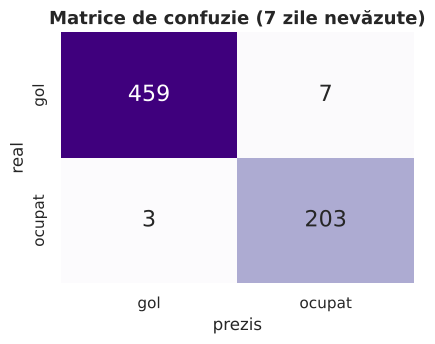

In [22]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
pred = heldout(lr)
ba, tr = bacc(y, pred), train_score(lr)
print(f"logistică, 36 trăsături: acur. echilibrată nevăzut = {ba:.3f} | antrenare = {tr:.3f}")
cm = confusion_matrix(y, pred); print(cm)
fig, ax = plt.subplots(figsize=(4.4, 3.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", cbar=False, xticklabels=["gol", "ocupat"], yticklabels=["gol", "ocupat"], ax=ax, annot_kws={"size": 16})
ax.set(xlabel="prezis", ylabel="real", title="Matrice de confuzie (7 zile nevăzute)"); plt.tight_layout(); plt.show()

**Citirea matricei de confuzie.** Rânduri = adevărul, coloane = predicția. 459 de ferestre goale sunt numite goale, 203 ferestre ocupate sunt găsite; **7 alarme false** (gol numit ocupat) și **3 ratări** (ocupat numit gol). Acuratețea = (459 + 203)/672 = 0,985; recall-ul clasei ocupat este 203/206 = 0,985, al clasei gol 459/466 = 0,985 — cele două erori nu costă la fel în practică (o ratare costă confort, o alarmă falsă costă energie), de aceea ne uităm mereu la matrice și nu doar la un singur număr.

## 4.3 · Arborele de decizie: o succesiune de întrebări

Un **arbore de decizie** împarte datele prin întrebări cu prag („este `tin_mean` > 22,1?”) alese astfel încât grupurile să fie cât mai *pure* (impuritatea Gini). Singurul lui parametru important este **adâncimea maximă**: un arbore puțin adânc este simplu, unul adânc poate memora datele de antrenare. Urmărim scorul de **antrenare** și cel pe **date nevăzute** pe măsură ce adâncimea crește.

 adâncime  antrenare  date nevăzute
        1      0.939          0.930
        2      0.975          0.962
        3      0.989          0.977
        4      0.998          0.975
        5      1.000          0.975
        6      1.000          0.975
        7      1.000          0.975
        8      1.000          0.975


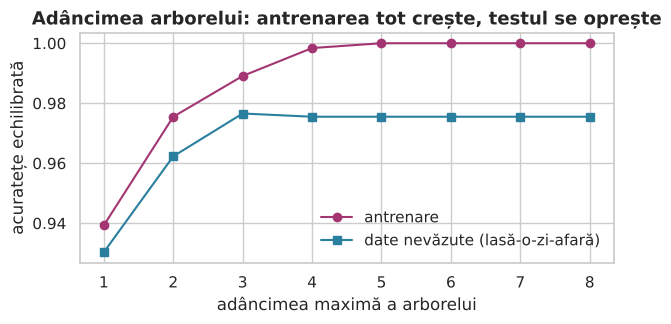

In [23]:
depths = range(1, 9); tr_, te_ = [], []
for dep in depths:
    t = DecisionTreeClassifier(max_depth=dep, random_state=0)
    tr_.append(train_score(t)); te_.append(bacc(y, heldout(t)))
res = pd.DataFrame({"adâncime": list(depths), "antrenare": np.round(tr_, 3), "date nevăzute": np.round(te_, 3)}); print(res.to_string(index=False))
fig, ax = plt.subplots(figsize=(6.4, 3.4)); ax.plot(depths, tr_, "-o", color=PINK, label="antrenare"); ax.plot(depths, te_, "-s", color=BLUE, label="date nevăzute (lasă-o-zi-afară)")
ax.set(xlabel="adâncimea maximă a arborelui", ylabel="acuratețe echilibrată", title="Adâncimea arborelui: antrenarea tot crește, testul se oprește"); ax.legend(); plt.tight_layout(); plt.show()

**Diagnostic.** Adâncimea 1 *subantrenează* (0,93 și pe antrenare, și pe date nevăzute: modelul este prea simplu). De la adâncimea 3 scorul pe date nevăzute este plat la ≈ 0,975, în timp ce scorul de antrenare continuă să urce până la 1,000: adâncimea în plus doar **memorează** zilele de antrenare. Alegerea corectă este **cel mai simplu model de pe platou**: adâncimea 3.

| Ce vedeți | Diagnostic | Ce încercați |
|---|---|---|
| antrenare joasă, test jos | **subantrenare** (prea simplu) | trăsături mai bogate, arbore mai adânc, regularizare mai slabă |
| antrenare ridicată, test mult mai mic | **supraantrenare** (prea flexibil) | model mai simplu, regularizare mai puternică, mai multe date, mai puține trăsături |
| antrenare ≈ test, ambele bune | modelul este potrivit | încetați reglajul |

## 4.4 · Regularizarea: o penalizare pe ponderile mari

Pentru regresia logistică „butonul” corespunzător este **regularizarea**: pierderea primește un termen în plus care penalizează ponderile mari, astfel încât modelul să nu se poată contorsiona ca să potrivească zgomotul. În scikit-learn intensitatea este controlată de `C = 1/λ`: **C mic = penalizare puternică = model simplu**, C mare = penalizare slabă. L2 micșorează toate ponderile lin; L1 (Partea 3) le oprește pe unele.

       C  antrenare  date nevăzute
  0.0001      0.500          0.500
  0.0010      0.932          0.930
  0.0100      0.967          0.965
  0.1000      0.988          0.973
  1.0000      0.996          0.985
 10.0000      0.999          0.982
100.0000      1.000          0.984


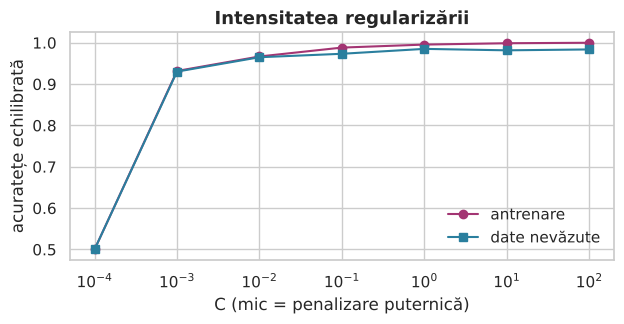

In [24]:
Cs = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]; tr_, te_ = [], []
for C in Cs:
    m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000)); tr_.append(train_score(m)); te_.append(bacc(y, heldout(m)))
print(pd.DataFrame({"C": Cs, "antrenare": np.round(tr_, 3), "date nevăzute": np.round(te_, 3)}).to_string(index=False))
fig, ax = plt.subplots(figsize=(6.4, 3.4)); ax.semilogx(Cs, tr_, "-o", color=PINK, label="antrenare"); ax.semilogx(Cs, te_, "-s", color=BLUE, label="date nevăzute")
ax.set(xlabel="C (mic = penalizare puternică)", ylabel="acuratețe echilibrată", title="Intensitatea regularizării"); ax.legend(); plt.tight_layout(); plt.show()

O penalizare prea puternică (`C = 0,0001`) striveste toate ponderile, iar modelul prezice o singură clasă (**0,50**: subantrenare); de la `C = 1` scorul pe date nevăzute se așază la ≈ 0,985, iar scorul de antrenare urcă încet spre 1,000 (un mic decalaj = supraantrenare ușoară). **Alegeți cel mai mic C de pe platou** (aici ≈ 1, care este și valoarea implicită). Hiperparametri precum `C` sau adâncimea trebuie aleși pe date de **validare**, niciodată pe ziua de test — Cursul 7 explică de ce.

## 4.5 · O variantă de regresie: câte persoane sunt?

Același tabel poate prezice **numărul de persoane** (`y_people`). Rețeta este identică; se schimbă doar **metrica**: **eroarea absolută medie (MAE)**, în persoane. Linia de bază este „prezic mereu numărul mediu de persoane”.

mereu media               3.83
liniar, doar media CO2    0.95
ridge, 36 trăsături       0.47
arbore, adâncime 3        0.43


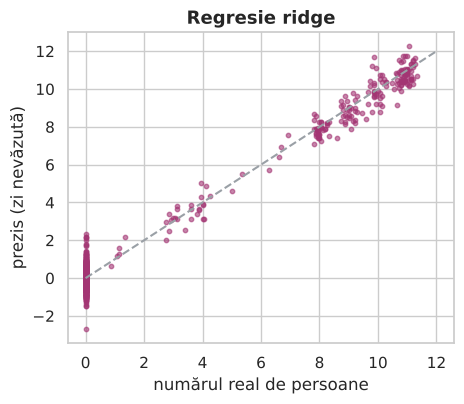

In [25]:
lin = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
models = {"mereu media": (DummyRegressor(), X), "liniar, doar media CO2": (LinearRegression(), X[["co2_mean"]]),
          "ridge, 36 trăsături": (lin, X), "arbore, adâncime 3": (DecisionTreeRegressor(max_depth=3, random_state=0), X)}
out = {}
for k, (m, Xm) in models.items():
    out[k] = cross_val_predict(m, Xm, y_people, cv=lodo, groups=day)
print(pd.Series({k: mae(y_people, p) for k, p in out.items()}).round(2).rename("MAE (persoane)").to_string())
fig, ax = plt.subplots(figsize=(4.8, 4.2)); ax.scatter(y_people, out["ridge, 36 trăsături"], s=10, color=PINK, alpha=0.6); ax.plot([0, 12], [0, 12], color=GREY, ls="--")
ax.set(xlabel="numărul real de persoane", ylabel="prezis (zi nevăzută)", title="Regresie ridge"); plt.tight_layout(); plt.show()

Linia de bază cu media greșește în medie cu **3,8 persoane**; o singură trăsătură (media CO₂) reduce deja eroarea la 0,95; ridge pe toate trăsăturile ajunge la **0,47**, un arbore de adâncime 3 la 0,43. Observați că modelele *simple* fac aproape toată treaba.

## 4.6 · Contează tipul de împărțire?

Comparăm o împărțire *aleatorie* în 5 fold-uri cu *lasă-o-zi-afară*, pe grupuri, pentru regresia logistică.

In [26]:
print("5 fold-uri aleatorii :", round(bacc(y, cross_val_predict(lr, X, y, cv=KFold(5, shuffle=True, random_state=0))), 3))
print("lasă-o-zi-afară      :", round(bacc(y, heldout(lr)), 3))
per_day = pd.Series({int(np.unique(day[b])[0]): accuracy_score(y[b], lr.fit(X.iloc[a], y[a]).predict(X.iloc[b])) for a, b in lodo.split(X, y, day)})
print("acuratețea pe fiecare zi nevăzută (Lun … Dum):", per_day.round(2).tolist())

5 fold-uri aleatorii : 0.982
lasă-o-zi-afară      : 0.985


acuratețea pe fiecare zi nevăzută (Lun … Dum): [0.98, 0.95, 0.99, 0.99, 0.99, 1.0, 1.0]


Aici cele două împărțiri dau același rezultat (≈ 0,98): ferestrele noastre fără suprapunere și datele ușoare și regulate ascund scurgerea de informație. **Asta nu face împărțirea aleatorie sigură**: în Partea 1 aceeași rețetă a dat 0,78 pe zgomot pur de îndată ce ferestrele s-au suprapus. Împărțirea pe grupuri nu costă nimic și vă protejează. Observați și **variația între zile** (0,95–1,00): cu 7 zile, o diferență de 0,01 între două modele nu este semnificativă — raportați media și variația, niciodată un singur număr.

## 4.7 · Primul tabel de rezultate

| Model | Acuratețe echilibrată pe date nevăzute | Comentariu |
|---|---|---|
| mereu „gol” | 0,500 | podeaua |
| prag pe `tin_mean` | 0,931 | linia de bază de depășit |
| regresie logistică, 36 trăsături | 0,985 | simplă, explicabilă |
| arbore de decizie, adâncime 3 | 0,977 | reguli ușor de citit |

> **Ce am învățat în Partea 4.** Linie de bază → model simplu → împărțire corectă → diagnostic → un remediu → tabel. Acuratețe echilibrată pentru clase dezechilibrate, MAE pentru numere. Antrenare vs test ne spune dacă trebuie să simplificăm sau să îmbogățim modelul; regularizarea (`C`) și adâncimea sunt primele butoane.

# Partea 5 — Punem totul cap la cap pe date reale

Aplicația finală folosește datele **reale** UCI *Room Occupancy Estimation*: 7 noduri de senzori într-o cameră de 4,6 m, un eșantion la 30 s, în 7 zile separate. Adevărul de referință este **numărul de persoane** (0–3). Repetăm rețeta completă — ferestre → trăsături → (selecție) → modele → tabel de rezultate — iar de data aceasta **nu se știe nimic dinainte**: datele sunt reale, zgomotoase, iar răspunsul ne poate surprinde.

## 5.1 · De la fișierul brut la un tabel de ferestre

`load_occupancy` agregă fiecare canal (temperatura a 4 noduri, lumina a 4 noduri, sunetul a 4 noduri, CO₂, panta CO₂, 2 senzori de mișcare PIR) în **ferestre de 5 minute** și calculează media, abaterea standard, minimul și maximul pe canal: un tabel de 1043 de ferestre × 24 de trăsături. Grupul este **ziua** (7 zile). Eticheta este *ocupat dacă numărul mediu de persoane din fereastră este peste 0,5*.

In [27]:
def load_occupancy(path="Occupancy_Estimation.csv", rule="5min"):
    d = pd.read_csv(path); d["ts"] = pd.to_datetime(d.Date + " " + d.Time); d = d.set_index("ts").drop(columns=["Date", "Time"])
    d["Temp"] = d[[f"S{i}_Temp" for i in range(1, 5)]].mean(axis=1); d["Light"] = d[[f"S{i}_Light" for i in range(1, 5)]].mean(axis=1)
    d["Sound"] = d[[f"S{i}_Sound" for i in range(1, 5)]].mean(axis=1); d["PIR"] = d[["S6_PIR", "S7_PIR"]].max(axis=1)
    r = d.resample(rule)
    g = r[["Temp", "Light", "Sound", "S5_CO2", "S5_CO2_Slope", "PIR", "Room_Occupancy_Count"]].agg(["mean", "std", "min", "max"])
    g.columns = ["_".join(c) for c in g.columns]; g = g[(r.size() >= 8).values].dropna()            # păstrăm ferestrele cu >= 8 din 10 eșantioane
    cnt = g["Room_Occupancy_Count_mean"].values; X = g.drop(columns=[c for c in g if c.startswith("Room")])
    return X, cnt, np.array([t.dayofyear for t in g.index])

Xo, cnt, dayo = load_occupancy(); yo = (cnt > 0.5).astype(int)
print("tabel:", Xo.shape, "| zile:", len(np.unique(dayo)), "| ferestre ocupate:", yo.sum(), f"({yo.mean():.1%})")
print(pd.crosstab(pd.Series(dayo, name="zi"), pd.Series(yo, name="ocupat")).T.to_string())

tabel: (1043, 24) | zile: 7 | ferestre ocupate: 195 (18.7%)
zi      10   11   356  357  358  359  360
ocupat                                   
0        72  108   66  206  110  177  109
1        31    0   83   81    0    0    0


Patru din cele șapte zile sunt **complet goale** (sărbători: 24, 25, 26 decembrie și 11 ianuarie); doar trei zile au persoane. Un model antrenat pe zilele 1–6 și testat pe o zi goală poate greși doar printr-o alarmă falsă; un test pe o zi ocupată măsoară detecția. **Raportați rezultatele pe fiecare zi**, nu doar media.

## 5.2 · Linii de bază și modele cu lasă-o-zi-afară

In [28]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
lodo = LeaveOneGroupOut()
def S(model, Xm, y=yo): return bacc(y, cross_val_predict(model, Xm, y, cv=lodo, groups=dayo))
LRm = lambda C=1.0: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))
print("clasa majoritară :", round(S(DummyClassifier(), Xo), 3))
single = pd.Series({c: S(DecisionTreeClassifier(max_depth=1, random_state=0), Xo[[c]]) for c in Xo.columns}).sort_values(ascending=False)
print("cele mai bune praguri pe o singură trăsătură:\n", single.head(5).round(3).to_string())

clasa majoritară : 0.5


cele mai bune praguri pe o singură trăsătură:
 PIR_max       0.991
Sound_mean    0.976
PIR_mean      0.974
Sound_max     0.969
Sound_std     0.968


**O surpriză.** Senzorul de mișcare singur (`PIR_max`: a existat mișcare în fereastră?) detectează ocuparea cu acuratețe echilibrată **0,99**. Un senzor PIR este *aproape chiar ținta*: a fost conceput să răspundă la „este cineva aici?”. Orice model care îl include va arăta excelent, dar este **util**? Dacă scopul este să estimăm ocuparea *fără* senzor PIR (mai ieftin, respectă viața privată, funcționează cu oameni care stau nemișcați), trebuie să **eliminăm trăsăturile PIR** și să vedem ce rămâne. Ambele versiuni sunt întrebări legitime — dar sunt întrebări diferite, iar raportul trebuie să spună la care s-a răspuns.

In [29]:
no_pir = [c for c in Xo.columns if not c.startswith("PIR")]
rows = []
def add(name, make, cols_):
    rows.append((name, len(cols_), round(S(make(), Xo[cols_]), 3)))
for label, cols_ in [("cu PIR", list(Xo.columns)), ("fără PIR", no_pir)]:
    add(f"{label}: regresie logistică", lambda: LRm(), cols_)
    add(f"{label}: regresie logistică, L1 (C=0,1)", lambda: make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=0.1, random_state=0)), cols_)
    add(f"{label}: arbore de decizie, adâncime 3", lambda: DecisionTreeClassifier(max_depth=3, random_state=0), cols_)
    add(f"{label}: pădure aleatorie (200 de arbori)", lambda: RandomForestClassifier(200, random_state=0, n_jobs=-1), cols_)
    add(f"{label}: RFE (4 trăsături) + logistică", lambda: make_pipeline(StandardScaler(), RFE(LogisticRegression(max_iter=3000), n_features_to_select=4), LogisticRegression(max_iter=3000)), cols_)
res = pd.DataFrame(rows, columns=["model", "trăsături", "acuratețe echilibrată"]); print(res.to_string(index=False))

                                     model  trăsături  acuratețe echilibrată
                cu PIR: regresie logistică         24                  0.984
    cu PIR: regresie logistică, L1 (C=0,1)         24                  0.991
     cu PIR: arbore de decizie, adâncime 3         24                  0.931
  cu PIR: pădure aleatorie (200 de arbori)         24                  0.948
     cu PIR: RFE (4 trăsături) + logistică         24                  0.979
              fără PIR: regresie logistică         20                  0.941
  fără PIR: regresie logistică, L1 (C=0,1)         20                  0.916
   fără PIR: arbore de decizie, adâncime 3         20                  0.965
fără PIR: pădure aleatorie (200 de arbori)         20                  0.945
   fără PIR: RFE (4 trăsături) + logistică         20                  0.921


Fără PIR, **cea mai bună trăsătură singură este `Sound_mean` (0,976)** — și *bate* orice model cu mai multe trăsături (0,92–0,965). Cu doar șapte zile, dintre care trei ocupate, modelele cu 20 de trăsături supraantrenează pe zilele pe care au fost antrenate. Exact de aceea **liniile de bază vin primele**: fără pragul pe o singură trăsătură am fi raportat „regresie logistică 0,94” și am fi crezut că e bine.

Contează tipul de împărțire aici? Date reale, suprapunere reală între senzori, un efect real de zi:

In [30]:
from sklearn.model_selection import KFold
m = LRm()
print("5 fold-uri aleatorii:", round(bacc(yo, cross_val_predict(m, Xo[no_pir], yo, cv=KFold(5, shuffle=True, random_state=0))), 3))
print("lasă-o-zi-afară     :", round(S(m, Xo[no_pir]), 3))

5 fold-uri aleatorii: 0.98
lasă-o-zi-afară     : 0.941


Împărțirea aleatorie raportează 0,98, cea pe grupuri de zile 0,94: **împărțirea aleatorie flatează modelul cu 4 puncte pe date reale** — estimarea adevărată a ce se întâmplă într-o *zi nouă* este cea pe grupuri.

## 5.3 · Regresie: câte persoane sunt?

Același tabel prezice numărul mediu de persoane din fereastră (0–3). Metrica: MAE, în persoane. Linia de bază: media.

In [31]:
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error as mae
out = {}
for k, m in {"mereu media": DummyRegressor(), "ridge (fără PIR)": make_pipeline(StandardScaler(), Ridge(1.0)), "arbore, adâncime 3 (fără PIR)": DecisionTreeRegressor(max_depth=3, random_state=0)}.items():
    out[k] = mae(cnt, cross_val_predict(m, Xo[no_pir], cnt, cv=lodo, groups=dayo))
print(pd.Series(out).round(3).rename("MAE (persoane)").to_string())

mereu media                      0.663
ridge (fără PIR)                 0.209
arbore, adâncime 3 (fără PIR)    0.146


Linia de bază cu media greșește cu 0,66 persoane; ridge și un arbore de adâncime 3 reduc eroarea la ≈ 0,15–0,21. Într-o cameră cu cel mult trei persoane, 0,15 persoane în medie este un număr util.

## 5.4 · Tabelul de rezultate pentru raport

| Întrebarea | Modelul | Rezultat pe date nevăzute (lasă-o-zi-afară) |
|---|---|---|
| ocupat? (toți senzorii) | clasa majoritară | 0,500 acuratețe echilibrată |
| ocupat? (toți senzorii) | prag pe `PIR_max` | **0,991** |
| ocupat? (fără PIR) | prag pe `Sound_mean` | **0,976** |
| ocupat? (fără PIR) | regresie logistică, 20 de trăsături | 0,941 |
| ocupat? (fără PIR) | arbore de decizie, adâncime 3 | 0,965 |
| numărul de persoane (fără PIR) | mereu media | MAE 0,66 |
| numărul de persoane (fără PIR) | arbore de decizie, adâncime 3 | MAE 0,15 |

**Limitări oneste de notat:** doar 7 zile, dintre care 3 cu persoane; eticheta provine dintr-o numărătoare făcută de oameni; diferențele sub ≈ 0,01–0,02 nu sunt semnificative; senzorul PIR este un înlocuitor al țintei și a fost exclus în a doua întrebare; camera și senzorii sunt fixe — nu spunem nimic despre alte camere.

> **Ce am învățat în Partea 5.** Pipeline-ul este mereu același; datele reale fac liniile de bază indispensabile (o singură trăsătură a bătut 20); o împărțire aleatorie poate flata un model cu mai multe puncte; un raport spune la ce întrebare s-a răspuns, cu ce trăsături și ce *nu* se pretinde.